# Experiment 188 · Temporal representation consistency

**Complete** · All temporal comparisons saved · ETA 0h 00m 00s  
393,216/393,216 new optimizer updates · PID 28160

All four arms use the same starting checkpoints, replay schedule and paired masks. Replay is 25% replacement with 25% broad history. Ordinary MAE, the view-compute zero-weight control and the same-frame noncontrastive arm come from Experiment 187. Twelve new temporal trajectories continue for 32,768 arrivals, with readouts at 8,192, 16,384 and 32,768.

Every eighth arrival, the temporal arm uses the current image and three past anchors. Each anchor is paired with a frame 16 cached positions earlier in the same clip when available. At the start of a clip, the pair uses the anchor twice. The same-frame arm uses the same anchors, augmentations, eight view encodes and optimizer steps. Both use the original 0.05-weighted pair MSE plus the per-view, per-dimension SD floor of 0.25.

The frozen temporal assay uses the same gap on unseen clips. It reports paired cosine, mean cross-clip cosine, their gap and cross-frame retrieval with same-clip negatives excluded. RankMe and feature variance measure collapse alongside these readouts. Final temporal assays use all four arms. Exact earlier checkpoints are available for the new arm, with the existing semantic and reconstruction readouts available at all scheduled points.

**Pairing audit:** 13,656/16,384 auxiliary pairs per trajectory use true temporal partners. Median raw RGB difference is 0.048 on the unlabeled holdout pairs, with pixels scaled to [0,1].

## Pre-training probe sensitivity

The audit uses the Experiment 187 same-frame and zero-weight endpoints. Hold the test panel fixed and refit on class-stratified 25%, 50%, and 100% fit sets with logistic C in {0.1, 1, 10}. Partial fit sets use three paired subsample draws. The table gives ranges of the paired same-frame gain across each factor, holding the other factors at the original protocol. Primary evaluation stays at full fit size, C=1 and the final layer. No task labels enter training or source selection.

| Task | Pairs | Default gain (pp) | Fit size range | Regularization range | Layer range | Effect floor (pp) |
| --- | --- | --- | --- | --- | --- | --- |
 | scene | 12 | +0.29 | [-0.86, +0.93] | [+0.15, +0.48] | [+0.08, +0.48] | 1.57 | 
 | weather | 12 | +0.21 | [-0.67, +0.21] | [-0.28, +0.21] | [+0.03, +0.33] | 0.50 | 
 | lighting | 12 | -0.00 | [-0.23, +0.24] | [-0.16, +0.08] | [-0.16, +0.00] | 0.50 | 
 | pedestrian | 12 | -0.39 | [-1.46, +0.26] | [-0.62, +0.16] | [-0.39, +0.42] | 0.78 | 

The effect floor is the larger of 0.5 pp and the median absolute gap between the two prior zero-weight mask draws within seed. At +32,768, a temporal contrast qualifies if at least two tasks exceed their floors, improve in four or more seeds, and have positive 95% seed-bootstrap lower bounds. Both MSE lower bounds must stay above −0.005. Intervals are descriptive and use both paired masks within each seed.

## Paired comparisons

| Arrivals | Comparison | Pairs | Unseen gain | Historical gain | View retrieval Δ (pp) | scene Δ (pp) | weather Δ (pp) | lighting Δ (pp) | pedestrian Δ (pp) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | 8192 | temporal vs same | 12 | +0.00029 | -0.00001 | -0.13021 | -0.32 | -0.28 | +0.24 | -0.36 | 
 | 8192 | temporal vs zero | 12 | +0.00178 | +0.00204 | +0.50456 | +0.11 | +0.39 | +0.08 | +0.44 | 
 | 8192 | same vs zero | 12 | +0.00149 | +0.00205 | +0.63477 | +0.43 | +0.67 | -0.16 | +0.81 | 
 | 8192 | zero vs mae | 12 | +0.00000 | +0.00000 | +0.00000 | +0.00 | +0.00 | +0.00 | +0.00 | 
 | 8192 | temporal vs mae | 12 | +0.00178 | +0.00204 | +0.50456 | +0.11 | +0.39 | +0.08 | +0.44 | 
 | 16384 | temporal vs same | 12 | -0.00196 | -0.00111 | +0.70801 | +0.63 | +0.36 | +0.08 | +0.39 | 
 | 16384 | temporal vs zero | 12 | -0.00172 | -0.00080 | +1.91243 | +0.40 | +0.72 | +0.00 | +0.31 | 
 | 16384 | same vs zero | 12 | +0.00025 | +0.00031 | +1.20443 | -0.23 | +0.36 | -0.08 | -0.08 | 
 | 16384 | zero vs mae | 12 | +0.00000 | +0.00000 | +0.00000 | +0.00 | +0.00 | +0.00 | +0.00 | 
 | 16384 | temporal vs mae | 12 | -0.00172 | -0.00080 | +1.91243 | +0.40 | +0.72 | +0.00 | +0.31 | 
 | 32768 | temporal vs same | 12 | -0.00369 | -0.00345 | +0.30924 | +0.14 | -0.03 | -0.08 | -0.49 | 
 | 32768 | temporal vs zero | 12 | -0.00260 | -0.00332 | +1.30208 | +0.43 | +0.18 | -0.08 | -0.89 | 
 | 32768 | same vs zero | 12 | +0.00109 | +0.00013 | +0.99284 | +0.29 | +0.21 | -0.00 | -0.39 | 
 | 32768 | zero vs mae | 12 | +0.00000 | +0.00000 | +0.00000 | +0.00 | +0.00 | +0.00 | +0.00 | 
 | 32768 | temporal vs mae | 12 | -0.00260 | -0.00332 | +1.30208 | +0.43 | +0.18 | -0.08 | -0.89 | 

| Arrivals | Comparison | frame_cosine | cross_clip_cosine | temporal_gap | temporal_retrieval | rankme | variance | seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | 8192 | temporal vs same | — | — | — | — | +0.08265 | -0.02734 | -1.12393 | 
 | 8192 | temporal vs zero | — | — | — | — | -0.10272 | -0.03670 | -0.96166 | 
 | 8192 | same vs zero | — | — | — | — | -0.18537 | -0.00935 | +0.16227 | 
 | 8192 | zero vs mae | — | — | — | — | +0.00000 | +0.00000 | +6.82848 | 
 | 8192 | temporal vs mae | — | — | — | — | -0.10272 | -0.03670 | +5.86682 | 
 | 16384 | temporal vs same | — | — | — | — | +0.02196 | -0.02331 | -11.73900 | 
 | 16384 | temporal vs zero | — | — | — | — | -0.19248 | -0.03671 | -12.12763 | 
 | 16384 | same vs zero | — | — | — | — | -0.21444 | -0.01340 | -0.38863 | 
 | 16384 | zero vs mae | — | — | — | — | +0.00000 | +0.00000 | +16.47341 | 
 | 16384 | temporal vs mae | — | — | — | — | -0.19248 | -0.03671 | +4.34579 | 
 | 32768 | temporal vs same | +0.00195 | +0.05176 | -0.04981 | -0.14022 | -0.13144 | -0.04316 | -19.58902 | 
 | 32768 | temporal vs zero | +0.00900 | +0.04033 | -0.03134 | -0.88141 | -0.36481 | -0.02609 | -17.97161 | 
 | 32768 | same vs zero | +0.00705 | -0.01142 | +0.01847 | -0.74119 | -0.23337 | +0.01707 | +1.61740 | 
 | 32768 | zero vs mae | +0.00000 | +0.00000 | +0.00000 | +0.00000 | +0.00000 | +0.00000 | +28.99084 | 
 | 32768 | temporal vs mae | +0.00900 | +0.04033 | -0.03134 | -0.88141 | -0.36481 | -0.02609 | +11.01923 | 

### Temporal versus same-frame, by encoder layer

| Task | Patch embedding · linear | Patch embedding · cosine 5-NN | Block 1 · linear | Block 1 · cosine 5-NN | Final normalized · linear | Final normalized · cosine 5-NN |
| --- | --- | --- | --- | --- | --- | --- |
 | scene | -0.49 pp | +0.34 pp | +0.06 pp | +0.15 pp | +0.14 pp | +0.20 pp | 
 | weather | -0.10 pp | -0.18 pp | -0.28 pp | +1.44 pp | -0.03 pp | +1.72 pp | 
 | lighting | +0.00 pp | +0.24 pp | +0.08 pp | +0.16 pp | -0.08 pp | +0.08 pp | 
 | pedestrian | -0.08 pp | -0.42 pp | -0.49 pp | -0.76 pp | -0.49 pp | +0.08 pp | 

### Final transfer criterion

| Reference | Qualifying tasks | Both MSE margins met | Pass |
| --- | --- | --- | --- |
 | same | None | False | False | 
 | zero | None | False | False | 

## Temporal trajectories

| Seed | Mask | Arrivals | Replay updates | Train time |
| --- | --- | --- | --- | --- |
 | 2029 | 1 | 32768 | 8192 | 0h 04m 49s | 
 | 2029 | 2 | 32768 | 8192 | 0h 04m 42s | 
 | 2030 | 1 | 32768 | 8192 | 0h 04m 45s | 
 | 2030 | 2 | 32768 | 8192 | 0h 04m 39s | 
 | 2031 | 1 | 32768 | 8192 | 0h 04m 42s | 
 | 2031 | 2 | 32768 | 8192 | 0h 04m 43s | 
 | 2032 | 1 | 32768 | 8192 | 0h 04m 44s | 
 | 2032 | 2 | 32768 | 8192 | 0h 04m 48s | 
 | 2033 | 1 | 32768 | 8192 | 0h 04m 50s | 
 | 2033 | 2 | 32768 | 8192 | 0h 04m 49s | 
 | 2034 | 1 | 32768 | 8192 | 0h 04m 49s | 
 | 2034 | 2 | 32768 | 8192 | 0h 04m 45s | 

In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-temporal-consistency')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


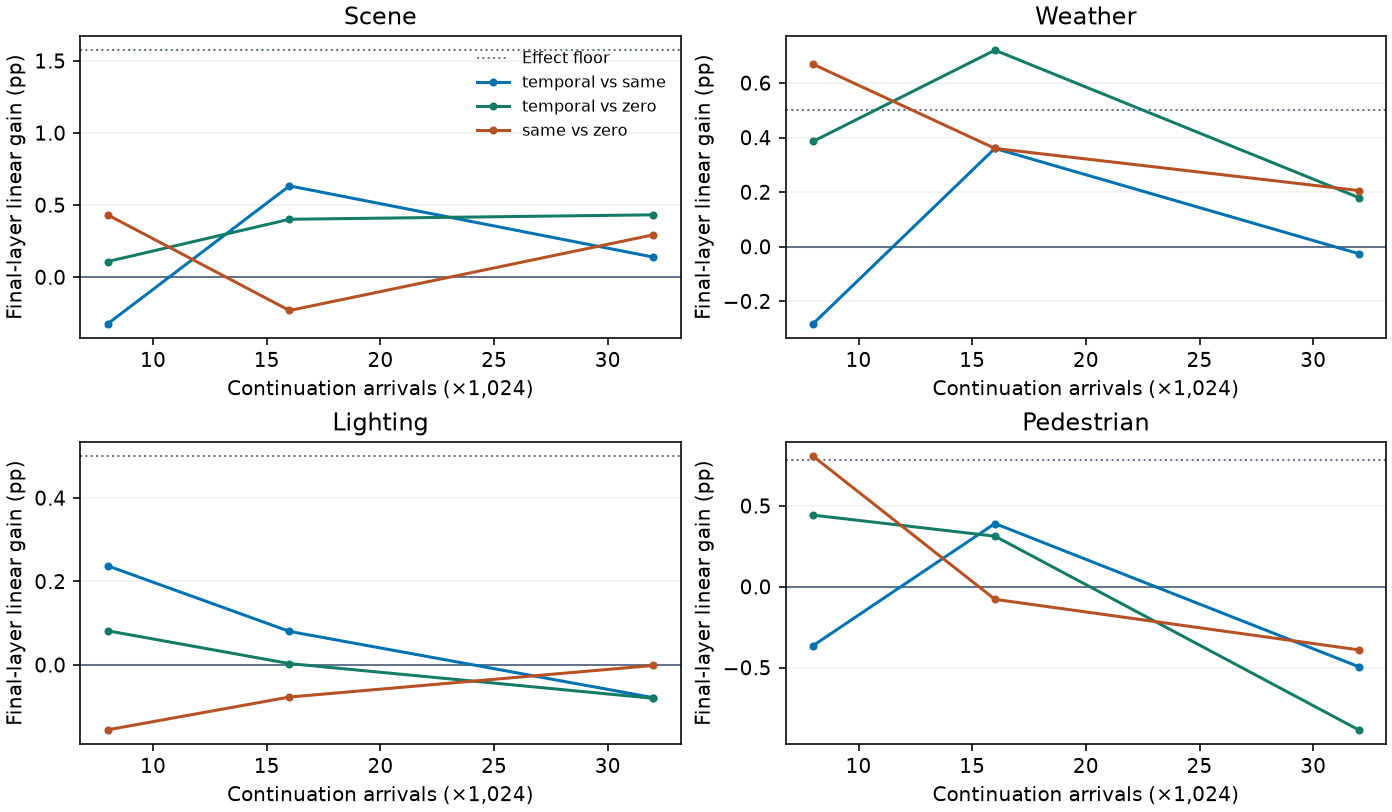